# HEAL: Stroke Risk Assessment
## Phase 5: Validation-Based Hyperparameter Optimization

Use Stratified 5-Fold Cross-Validation on the training set to tune primary candidate models and lock the decision threshold.

## Objective
Tune candidate models and select the operating threshold using cross-validation strictly within the 4,842-sample training cohort, keeping the 1,211-sample test set completely untouched.

## Data & Partitioning
- Dataset: `stroke_cleaned_dataset_corrected.csv` (6,053 rows, 6 features, 1 target).
- **Training Cohort:** $N = 4,842$ (4,618 non-stroke, 224 stroke; 4.63% prevalence) — used for all CV tuning.
- **Test Cohort (LOCKED):** $N = 1,211$ (1,155 non-stroke, 56 stroke) — kept quarantined until Phase 6.

## Methodology
- **Stratified 5-Fold CV:** Split the training data into 5 folds while preserving class proportions.
- **Strict Leakage Prevention:** `StandardScaler`, sample weighting, and SMOTE are fitted strictly on each training fold. Validation folds remain untouched.
- **Selection Metric:** We prioritize Mean CV PR-AUC (Average Precision) over accuracy and ROC-AUC.
- **Threshold Selection:** Out-of-fold (OOF) validation predictions are evaluated across thresholds $	au \in [0.10, 0.50]$ to balance sensitivity and specificity.

### Imports & Setup
Import libraries, load data, and confirm the 80/20 train/test split.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix, precision_recall_curve, roc_curve, ConfusionMatrixDisplay
)
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_sample_weight

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# 1. Load dataset
data_path = "stroke_cleaned_dataset_corrected.csv"
df = pd.read_csv(data_path)
features = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'Diabetes', 'HbA1c', 'Smoker']
target = 'Stroke'

X = df[features].copy()
y = df[target].copy()

# 2. Existing Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dataset successfully loaded: {df.shape[0]:,} total samples.")
print(f"Features: {features}")
print(f"Training Cohort: N = {len(X_train):,} (Non-Stroke: {(y_train == 0).sum():,}, Stroke: {(y_train == 1).sum():,}, Prev: {y_train.mean()*100:.2f}%)")
print(f"Held-Out Test Set (LOCKED & UNTOUCHED): N = {len(X_test):,} (Non-Stroke: {(y_test == 0).sum():,}, Stroke: {(y_test == 1).sum():,}, Prev: {y_test.mean()*100:.2f}%)")

# Strict isolation assertions
assert len(X_train) == 4842, f"Expected 4842 train samples, got {len(X_train)}"
assert len(X_test) == 1211, f"Expected 1211 test samples, got {len(X_test)}"
print("[OK] Test set confirmed quarantined and locked.")

Dataset successfully loaded: 6,053 total samples.
Features: ['Systolic_BP', 'Diastolic_BP', 'BMI', 'Diabetes', 'HbA1c', 'Smoker']
Training Cohort: N = 4,842 (Non-Stroke: 4,618, Stroke: 224, Prev: 4.63%)
Held-Out Test Set (LOCKED & UNTOUCHED): N = 1,211 (Non-Stroke: 1,155, Stroke: 56, Prev: 4.62%)
[OK] Test set confirmed quarantined and locked.


### Cross-Validation Engine
Define `evaluate_cv_configuration` to run 5-fold CV with within-fold preprocessing and out-of-fold probability tracking.

In [2]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Systolic_BP', 'Diastolic_BP', 'BMI', 'HbA1c']),
        ('cat', 'passthrough', ['Diabetes', 'Smoker'])
    ]
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_cv_configuration(model_family, imbalance_method, model_creator, is_smote=False, smote_params=None, is_weighted=False):
    oof_probs = np.zeros(len(X_train))
    fold_pr_auc = []
    fold_roc_auc = []
    fold_recall = []
    fold_precision = []
    fold_f1 = []
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        
        # Fit preprocessor strictly on training fold
        X_tr_trans = preprocessor.fit_transform(X_tr)
        X_val_trans = preprocessor.transform(X_val)
        
        clf = model_creator()
        
        if is_smote:
            sm = SMOTE(random_state=42, **smote_params)
            X_tr_res, y_tr_res = sm.fit_resample(X_tr_trans, y_tr)
            clf.fit(X_tr_res, y_tr_res)
        elif is_weighted:
            sw = compute_sample_weight('balanced', y_tr)
            clf.fit(X_tr_trans, y_tr, sample_weight=sw)
        else:
            clf.fit(X_tr_trans, y_tr)
            
        probs = clf.predict_proba(X_val_trans)[:, 1]
        oof_probs[val_idx] = probs
        
        preds = (probs >= 0.50).astype(int)
        fold_pr_auc.append(average_precision_score(y_val, probs))
        fold_roc_auc.append(roc_auc_score(y_val, probs))
        fold_recall.append(recall_score(y_val, preds, zero_division=0))
        fold_precision.append(precision_score(y_val, preds, zero_division=0))
        fold_f1.append(f1_score(y_val, preds, zero_division=0))
        
    return {
        'mean_pr_auc': np.mean(fold_pr_auc),
        'std_pr_auc': np.std(fold_pr_auc),
        'mean_roc_auc': np.mean(fold_roc_auc),
        'std_roc_auc': np.std(fold_roc_auc),
        'mean_recall': np.mean(fold_recall),
        'mean_precision': np.mean(fold_precision),
        'mean_f1': np.mean(fold_f1),
        'oof_pr_auc': average_precision_score(y_train, oof_probs),
        'oof_roc_auc': roc_auc_score(y_train, oof_probs),
        'oof_probs': oof_probs
    }

print("5-Fold Cross-Validation evaluation engine successfully initialized.")

5-Fold Cross-Validation evaluation engine successfully initialized.


### Hyperparameter Grid Search
Run 5-fold CV across 34 configurations:
1. Logistic Regression + balanced weights (10 configs: $C \in [0.01, 100.0]$, solvers `liblinear` and `lbfgs`).
2. Gradient Boosting + balanced sample weights (12 configs: depths 2–3, learning rates 0.03–0.10, estimators 50–150).
3. Gradient Boosting + SMOTE (12 configs: SMOTE ratios 0.3–1.0, $k$-neighbors 3–5, shallow depth 2–3).

In [3]:
results_records = []
oof_predictions_dict = {}

# 1. Logistic Regression + class_weight='balanced'
print("--- 1. Evaluating Logistic Regression + class_weight='balanced' ---")
lr_C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
lr_solvers = ['liblinear', 'lbfgs']

for C in lr_C_values:
    for solver in lr_solvers:
        cfg_name = f"LR_balanced_C={C}_solver={solver}"
        res = evaluate_cv_configuration(
            model_family="Logistic Regression",
            imbalance_method="class_weight='balanced'",
            model_creator=lambda c=C, s=solver: LogisticRegression(
                C=c, solver=s, class_weight='balanced', max_iter=1000, random_state=42
            )
        )
        oof_predictions_dict[cfg_name] = res['oof_probs']
        results_records.append({
            'Model_Family': 'Logistic Regression',
            'Imbalance_Method': "class_weight='balanced'",
            'Config_Name': cfg_name,
            'Hyperparameters': f"C={C}, solver={solver}, penalty=l2",
            'C': C, 'solver': solver,
            'n_estimators': np.nan, 'learning_rate': np.nan, 'max_depth': np.nan,
            'min_samples_split': np.nan, 'min_samples_leaf': np.nan,
            'smote_sampling_strategy': np.nan, 'smote_k_neighbors': np.nan,
            'Mean_CV_PR_AUC': res['mean_pr_auc'], 'Std_CV_PR_AUC': res['std_pr_auc'],
            'Mean_CV_ROC_AUC': res['mean_roc_auc'], 'Std_CV_ROC_AUC': res['std_roc_auc'],
            'Mean_CV_Recall_0.50': res['mean_recall'], 'Mean_CV_Precision_0.50': res['mean_precision'],
            'Mean_CV_F1_0.50': res['mean_f1'], 'OOF_PR_AUC': res['oof_pr_auc'], 'OOF_ROC_AUC': res['oof_roc_auc']
        })
        print(f"  {cfg_name}: Mean PR-AUC = {res['mean_pr_auc']:.4f} (+/- {res['std_pr_auc']:.4f}), ROC-AUC = {res['mean_roc_auc']:.4f}")

# 2. Gradient Boosting + balanced sample weighting
print("\n--- 2. Evaluating Gradient Boosting + balanced sample weighting ---")
gb_weighted_grid = [
    {'n_estimators': 100, 'learning_rate': 0.10, 'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 1},
    {'n_estimators': 50,  'learning_rate': 0.03, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'n_estimators': 50,  'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'n_estimators': 100, 'learning_rate': 0.03, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'n_estimators': 100, 'learning_rate': 0.10, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'n_estimators': 150, 'learning_rate': 0.03, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'n_estimators': 150, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 20, 'min_samples_leaf': 10},
    {'n_estimators': 50,  'learning_rate': 0.05, 'max_depth': 3, 'min_samples_split': 20, 'min_samples_leaf': 10},
    {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'min_samples_split': 20, 'min_samples_leaf': 10},
    {'n_estimators': 100, 'learning_rate': 0.10, 'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 5}
]

for p in gb_weighted_grid:
    cfg_name = f"GB_weighted_est={p['n_estimators']}_lr={p['learning_rate']}_depth={p['max_depth']}_split={p['min_samples_split']}_leaf={p['min_samples_leaf']}"
    res = evaluate_cv_configuration(
        model_family="Gradient Boosting",
        imbalance_method="sample_weight='balanced'",
        model_creator=lambda params=p: GradientBoostingClassifier(
            n_estimators=params['n_estimators'], learning_rate=params['learning_rate'],
            max_depth=params['max_depth'], min_samples_split=params['min_samples_split'],
            min_samples_leaf=params['min_samples_leaf'], random_state=42
        ),
        is_weighted=True
    )
    oof_predictions_dict[cfg_name] = res['oof_probs']
    results_records.append({
        'Model_Family': 'Gradient Boosting',
        'Imbalance_Method': "sample_weight='balanced'",
        'Config_Name': cfg_name,
        'Hyperparameters': f"n_est={p['n_estimators']}, lr={p['learning_rate']}, depth={p['max_depth']}, split={p['min_samples_split']}, leaf={p['min_samples_leaf']}",
        'C': np.nan, 'solver': np.nan,
        'n_estimators': p['n_estimators'], 'learning_rate': p['learning_rate'], 'max_depth': p['max_depth'],
        'min_samples_split': p['min_samples_split'], 'min_samples_leaf': p['min_samples_leaf'],
        'smote_sampling_strategy': np.nan, 'smote_k_neighbors': np.nan,
        'Mean_CV_PR_AUC': res['mean_pr_auc'], 'Std_CV_PR_AUC': res['std_pr_auc'],
        'Mean_CV_ROC_AUC': res['mean_roc_auc'], 'Std_CV_ROC_AUC': res['std_roc_auc'],
        'Mean_CV_Recall_0.50': res['mean_recall'], 'Mean_CV_Precision_0.50': res['mean_precision'],
        'Mean_CV_F1_0.50': res['mean_f1'], 'OOF_PR_AUC': res['oof_pr_auc'], 'OOF_ROC_AUC': res['oof_roc_auc']
    })
    print(f"  {cfg_name}: Mean PR-AUC = {res['mean_pr_auc']:.4f} (+/- {res['std_pr_auc']:.4f}), ROC-AUC = {res['mean_roc_auc']:.4f}")

# 3. Gradient Boosting + SMOTE
print("\n--- 3. Evaluating Gradient Boosting + SMOTE ---")
gb_smote_grid = [
    {'smote_ratio': 1.0, 'k_neighbors': 5, 'n_estimators': 100, 'learning_rate': 0.10, 'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 1},
    {'smote_ratio': 0.3, 'k_neighbors': 3, 'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 0.3, 'k_neighbors': 5, 'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 0.5, 'k_neighbors': 3, 'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 0.5, 'k_neighbors': 5, 'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 1.0, 'k_neighbors': 3, 'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 1.0, 'k_neighbors': 5, 'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 0.5, 'k_neighbors': 5, 'n_estimators': 50,  'learning_rate': 0.05, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 0.5, 'k_neighbors': 5, 'n_estimators': 100, 'learning_rate': 0.03, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 0.5, 'k_neighbors': 5, 'n_estimators': 100, 'learning_rate': 0.10, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 0.5, 'k_neighbors': 5, 'n_estimators': 150, 'learning_rate': 0.03, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 5},
    {'smote_ratio': 0.5, 'k_neighbors': 5, 'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 5}
]

for p in gb_smote_grid:
    cfg_name = f"GB_SMOTE_ratio={p['smote_ratio']}_k={p['k_neighbors']}_est={p['n_estimators']}_lr={p['learning_rate']}_depth={p['max_depth']}"
    res = evaluate_cv_configuration(
        model_family="Gradient Boosting",
        imbalance_method="SMOTE (train fold only)",
        model_creator=lambda params=p: GradientBoostingClassifier(
            n_estimators=params['n_estimators'], learning_rate=params['learning_rate'],
            max_depth=params['max_depth'], min_samples_split=params['min_samples_split'],
            min_samples_leaf=params['min_samples_leaf'], random_state=42
        ),
        is_smote=True,
        smote_params={'sampling_strategy': p['smote_ratio'], 'k_neighbors': p['k_neighbors']}
    )
    oof_predictions_dict[cfg_name] = res['oof_probs']
    results_records.append({
        'Model_Family': 'Gradient Boosting',
        'Imbalance_Method': 'SMOTE (train fold only)',
        'Config_Name': cfg_name,
        'Hyperparameters': f"SMOTE(ratio={p['smote_ratio']}, k={p['k_neighbors']}), n_est={p['n_estimators']}, lr={p['learning_rate']}, depth={p['max_depth']}",
        'C': np.nan, 'solver': np.nan,
        'n_estimators': p['n_estimators'], 'learning_rate': p['learning_rate'], 'max_depth': p['max_depth'],
        'min_samples_split': p['min_samples_split'], 'min_samples_leaf': p['min_samples_leaf'],
        'smote_sampling_strategy': p['smote_ratio'], 'smote_k_neighbors': p['k_neighbors'],
        'Mean_CV_PR_AUC': res['mean_pr_auc'], 'Std_CV_PR_AUC': res['std_pr_auc'],
        'Mean_CV_ROC_AUC': res['mean_roc_auc'], 'Std_CV_ROC_AUC': res['std_roc_auc'],
        'Mean_CV_Recall_0.50': res['mean_recall'], 'Mean_CV_Precision_0.50': res['mean_precision'],
        'Mean_CV_F1_0.50': res['mean_f1'], 'OOF_PR_AUC': res['oof_pr_auc'], 'OOF_ROC_AUC': res['oof_roc_auc']
    })
    print(f"  {cfg_name}: Mean PR-AUC = {res['mean_pr_auc']:.4f} (+/- {res['std_pr_auc']:.4f}), ROC-AUC = {res['mean_roc_auc']:.4f}")

results_df = pd.DataFrame(results_records).sort_values(by='Mean_CV_PR_AUC', ascending=False)
results_df.to_csv("phase5_hyperparameter_results.csv", index=False)
print("\n[OK] Complete hyperparameter optimization records saved to 'phase5_hyperparameter_results.csv'.")

--- 1. Evaluating Logistic Regression + class_weight='balanced' ---
  LR_balanced_C=0.01_solver=liblinear: Mean PR-AUC = 0.1076 (+/- 0.0160), ROC-AUC = 0.7220
  LR_balanced_C=0.01_solver=lbfgs: Mean PR-AUC = 0.1075 (+/- 0.0155), ROC-AUC = 0.7226
  LR_balanced_C=0.1_solver=liblinear: Mean PR-AUC = 0.1081 (+/- 0.0158), ROC-AUC = 0.7244
  LR_balanced_C=0.1_solver=lbfgs: Mean PR-AUC = 0.1082 (+/- 0.0158), ROC-AUC = 0.7242
  LR_balanced_C=1.0_solver=liblinear: Mean PR-AUC = 0.1082 (+/- 0.0162), ROC-AUC = 0.7243


  LR_balanced_C=1.0_solver=lbfgs: Mean PR-AUC = 0.1082 (+/- 0.0161), ROC-AUC = 0.7243


  LR_balanced_C=10.0_solver=liblinear: Mean PR-AUC = 0.1082 (+/- 0.0162), ROC-AUC = 0.7243
  LR_balanced_C=10.0_solver=lbfgs: Mean PR-AUC = 0.1082 (+/- 0.0162), ROC-AUC = 0.7243
  LR_balanced_C=100.0_solver=liblinear: Mean PR-AUC = 0.1082 (+/- 0.0162), ROC-AUC = 0.7243
  LR_balanced_C=100.0_solver=lbfgs: Mean PR-AUC = 0.1082 (+/- 0.0162), ROC-AUC = 0.7242

--- 2. Evaluating Gradient Boosting + balanced sample weighting ---


  GB_weighted_est=100_lr=0.1_depth=3_split=2_leaf=1: Mean PR-AUC = 0.0862 (+/- 0.0089), ROC-AUC = 0.6635


  GB_weighted_est=50_lr=0.03_depth=2_split=10_leaf=5: Mean PR-AUC = 0.0960 (+/- 0.0117), ROC-AUC = 0.7204


...

  GB_SMOTE_ratio=0.5_k=5_est=50_lr=0.05_depth=2: Mean PR-AUC = 0.0902 (+/- 0.0107), ROC-AUC = 0.7142


  GB_SMOTE_ratio=0.5_k=5_est=100_lr=0.03_depth=2: Mean PR-AUC = 0.0890 (+/- 0.0110), ROC-AUC = 0.7120


  GB_SMOTE_ratio=0.5_k=5_est=100_lr=0.1_depth=2: Mean PR-AUC = 0.0884 (+/- 0.0148), ROC-AUC = 0.6954


  GB_SMOTE_ratio=0.5_k=5_est=150_lr=0.03_depth=2: Mean PR-AUC = 0.0914 (+/- 0.0106), ROC-AUC = 0.7071


  GB_SMOTE_ratio=0.5_k=5_est=100_lr=0.05_depth=3: Mean PR-AUC = 0.0843 (+/- 0.0090), ROC-AUC = 0.6870

[OK] Complete hyperparameter optimization records saved to 'phase5_hyperparameter_results.csv'.


### Top Configurations Table
Review the top configurations ranked by Mean CV PR-AUC.

In [4]:
display_cols = [
    'Model_Family', 'Imbalance_Method', 'Hyperparameters',
    'Mean_CV_PR_AUC', 'Std_CV_PR_AUC', 'Mean_CV_ROC_AUC', 'OOF_PR_AUC', 'OOF_ROC_AUC'
]
print("--- Top 15 Hyperparameter Configurations (Ranked by Mean CV PR-AUC) ---")
results_df[display_cols].head(15).round(4)

--- Top 15 Hyperparameter Configurations (Ranked by Mean CV PR-AUC) ---


,Model_Family,Imbalance_Method,Hyperparameters,Mean_CV_PR_AUC,Std_CV_PR_AUC,Mean_CV_ROC_AUC,OOF_PR_AUC,OOF_ROC_AUC
4,Logistic Regression,class_weight='balanced',"C=1.0, solver=liblinear, penalty=l2",0.1082,0.0162,0.7243,0.0980,0.7227
7,Logistic Regression,class_weight='balanced',"C=10.0, solver=lbfgs, penalty=l2",0.1082,0.0162,0.7243,0.0980,0.7226
9,Logistic Regression,class_weight='balanced',"C=100.0, solver=lbfgs, penalty=l2",0.1082,0.0162,0.7242,0.0980,0.7226
6,Logistic Regression,class_weight='balanced',"C=10.0, solver=liblinear, penalty=l2",0.1082,0.0162,0.7243,0.0979,0.7226
5,Logistic Regression,class_weight='balanced',"C=1.0, solver=lbfgs, penalty=l2",0.1082,0.0161,0.7243,0.0980,0.7227
3,Logistic Regression,class_weight='balanced',"C=0.1, solver=lbfgs, penalty=l2",0.1082,0.0158,0.7242,0.0978,0.7226
8,Logistic Regression,class_weight='balanced',"C=100.0, solver=liblinear, penalty=l2",0.1082,0.0162,0.7243,0.0979,0.7226
2,Logistic Regression,class_weight='balanced',"C=0.1, solver=liblinear, penalty=l2",0.1081,0.0158,0.7244,0.0975,0.7227
0,Logistic Regression,class_weight='balanced',"C=0.01, solver=liblinear, penalty=l2",0.1076,0.0160,0.7220,0.0967,0.7200
1,Logistic Regression,class_weight='balanced',"C=0.01, solver=lbfgs, penalty=l2",0.1075,0.0155,0.7226,0.0970,0.7206


### Top Candidate per Family
Compare the best configuration from each model family.

In [5]:
top_lr = results_df[results_df['Model_Family'] == 'Logistic Regression'].iloc[0]
top_gb_weighted = results_df[(results_df['Model_Family'] == 'Gradient Boosting') & (results_df['Imbalance_Method'] == "sample_weight='balanced'")].iloc[0]
top_gb_smote = results_df[(results_df['Model_Family'] == 'Gradient Boosting') & (results_df['Imbalance_Method'] == "SMOTE (train fold only)")].iloc[0]

summary_top = pd.DataFrame([
    {
        'Candidate Family': 'Logistic Regression (Weighted)',
        'Winning Configuration': top_lr['Config_Name'],
        'Hyperparameters': top_lr['Hyperparameters'],
        'Mean CV PR-AUC': f"{top_lr['Mean_CV_PR_AUC']:.4f} (+/- {top_lr['Std_CV_PR_AUC']:.4f})",
        'Mean CV ROC-AUC': f"{top_lr['Mean_CV_ROC_AUC']:.4f} (+/- {top_lr['Std_CV_ROC_AUC']:.4f})",
        'OOF PR-AUC': f"{top_lr['OOF_PR_AUC']:.4f}",
        'OOF ROC-AUC': f"{top_lr['OOF_ROC_AUC']:.4f}"
    },
    {
        'Candidate Family': 'Gradient Boosting (Sample-Weighted)',
        'Winning Configuration': top_gb_weighted['Config_Name'],
        'Hyperparameters': top_gb_weighted['Hyperparameters'],
        'Mean CV PR-AUC': f"{top_gb_weighted['Mean_CV_PR_AUC']:.4f} (+/- {top_gb_weighted['Std_CV_PR_AUC']:.4f})",
        'Mean CV ROC-AUC': f"{top_gb_weighted['Mean_CV_ROC_AUC']:.4f} (+/- {top_gb_weighted['Std_CV_ROC_AUC']:.4f})",
        'OOF PR-AUC': f"{top_gb_weighted['OOF_PR_AUC']:.4f}",
        'OOF ROC-AUC': f"{top_gb_weighted['OOF_ROC_AUC']:.4f}"
    },
    {
        'Candidate Family': 'Gradient Boosting (SMOTE)',
        'Winning Configuration': top_gb_smote['Config_Name'],
        'Hyperparameters': top_gb_smote['Hyperparameters'],
        'Mean CV PR-AUC': f"{top_gb_smote['Mean_CV_PR_AUC']:.4f} (+/- {top_gb_smote['Std_CV_PR_AUC']:.4f})",
        'Mean CV ROC-AUC': f"{top_gb_smote['Mean_CV_ROC_AUC']:.4f} (+/- {top_gb_smote['Std_CV_ROC_AUC']:.4f})",
        'OOF PR-AUC': f"{top_gb_smote['OOF_PR_AUC']:.4f}",
        'OOF ROC-AUC': f"{top_gb_smote['OOF_ROC_AUC']:.4f}"
    }
])

summary_top

,Candidate Family,Winning Configuration,Hyperparameters,Mean CV PR-AUC,Mean CV ROC-AUC,OOF PR-AUC,OOF ROC-AUC
0,Logistic Regression (Weighted),LR_balanced_C=1.0_solver=liblinear,"C=1.0, solver=liblinear, penalty=l2",0.1082 (+/- 0.0162),0.7243 (+/- 0.0334),0.0980,0.7227
1,Gradient Boosting (Sample-Weighted),GB_weighted_est=100_lr=0.1_depth=2_split=10_le...,"n_est=100, lr=0.1, depth=2, split=10, leaf=5",0.1056 (+/- 0.0208),0.7002 (+/- 0.0420),0.0942,0.6972
2,Gradient Boosting (SMOTE),GB_SMOTE_ratio=0.5_k=3_est=100_lr=0.05_depth=2,"SMOTE(ratio=0.5, k=3), n_est=100, lr=0.05, dep...",0.0952 (+/- 0.0178),0.6985 (+/- 0.0439),0.0846,0.6971


### Selection Metric Rationale (PR-AUC)
- Accuracy is misleading: a naive model predicting zero strokes gets 95.37% accuracy but 0.0% sensitivity.
- ROC-AUC is lenient: the large negative class keeps false positive rates low even with hundreds of false alarms.
- PR-AUC directly tracks precision and recall on the minority class, making it the most clinically relevant metric.

### Threshold Selection on Validation (OOF) Predictions
Scan decision thresholds $	au \in [0.10, 0.50]$ on the 4,842 out-of-fold validation predictions to choose the operating point.

In [6]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
threshold_records = []

candidates_for_threshold = [
    ('Logistic Regression (Weighted)', top_lr['Config_Name']),
    ('Gradient Boosting (Weighted)', top_gb_weighted['Config_Name']),
    ('Gradient Boosting (SMOTE)', top_gb_smote['Config_Name'])
]

for display_name, cfg_id in candidates_for_threshold:
    oof_p = oof_predictions_dict[cfg_id]
    for t in thresholds:
        preds = (oof_p >= t).astype(int)
        cm = confusion_matrix(y_train, preds)
        tn, fp, fn, tp = cm.ravel()
        prec = precision_score(y_train, preds, zero_division=0)
        rec = recall_score(y_train, preds, zero_division=0)
        f1 = f1_score(y_train, preds, zero_division=0)
        spec = tn / (tn + fp)
        threshold_records.append({
            'Candidate': display_name,
            'Config_Name': cfg_id,
            'Threshold': t,
            'Precision': prec,
            'Recall (Sens)': rec,
            'Specificity': spec,
            'F1-Score': f1,
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn
        })

df_thresholds = pd.DataFrame(threshold_records)

# Filter for the strongest candidate: Logistic Regression
best_cfg_id = top_lr['Config_Name']
best_thresh_df = df_thresholds[df_thresholds['Config_Name'] == best_cfg_id]
print("--- Validation Out-of-Fold Threshold Analysis for Strongest Candidate (LR Balanced) ---")
best_thresh_df[['Threshold', 'Recall (Sens)', 'Specificity', 'Precision', 'F1-Score', 'TP', 'FP', 'FN', 'TN']].round(4)

--- Validation Out-of-Fold Threshold Analysis for Strongest Candidate (LR Balanced) ---


,Threshold,Recall (Sens),Specificity,Precision,F1-Score,TP,FP,FN,TN
0,0.10,1.0000,0.0000,0.0463,0.0884,224,4618,0,0
1,0.15,1.0000,0.0002,0.0463,0.0885,224,4617,0,1
2,0.20,0.9911,0.0372,0.0476,0.0908,222,4446,2,172
3,0.25,0.9688,0.1914,0.0549,0.1040,217,3734,7,884
4,0.30,0.9196,0.3660,0.0657,0.1227,206,2928,18,1690
5,0.35,0.8705,0.4584,0.0723,0.1336,195,2501,29,2117
6,0.40,0.8125,0.5039,0.0736,0.1350,182,2291,42,2327
7,0.45,0.7812,0.5626,0.0797,0.1447,175,2020,49,2598
8,0.50,0.6920,0.6479,0.0870,0.1546,155,1626,69,2992


### Locked Model & Decision Threshold
Based on cross-validation and OOF validation:
- **Locked Model:** `LogisticRegression(class_weight='balanced', C=1.0, solver='liblinear', penalty='l2', max_iter=1000, random_state=42)`
- **Locked Threshold:** $	au = 0.45$
- At $	au = 0.45$, validation sensitivity is 78.12% (175/224 strokes caught) with 56.26% specificity (2,598 cleared), catching 20 more stroke cases than the default 0.50 threshold.

## Diagnostic Visualizations
Visualize hyperparameter comparisons, out-of-fold PR/ROC curves, and threshold trade-offs.

### Hyperparameter Comparison & Regularization Sensitivity

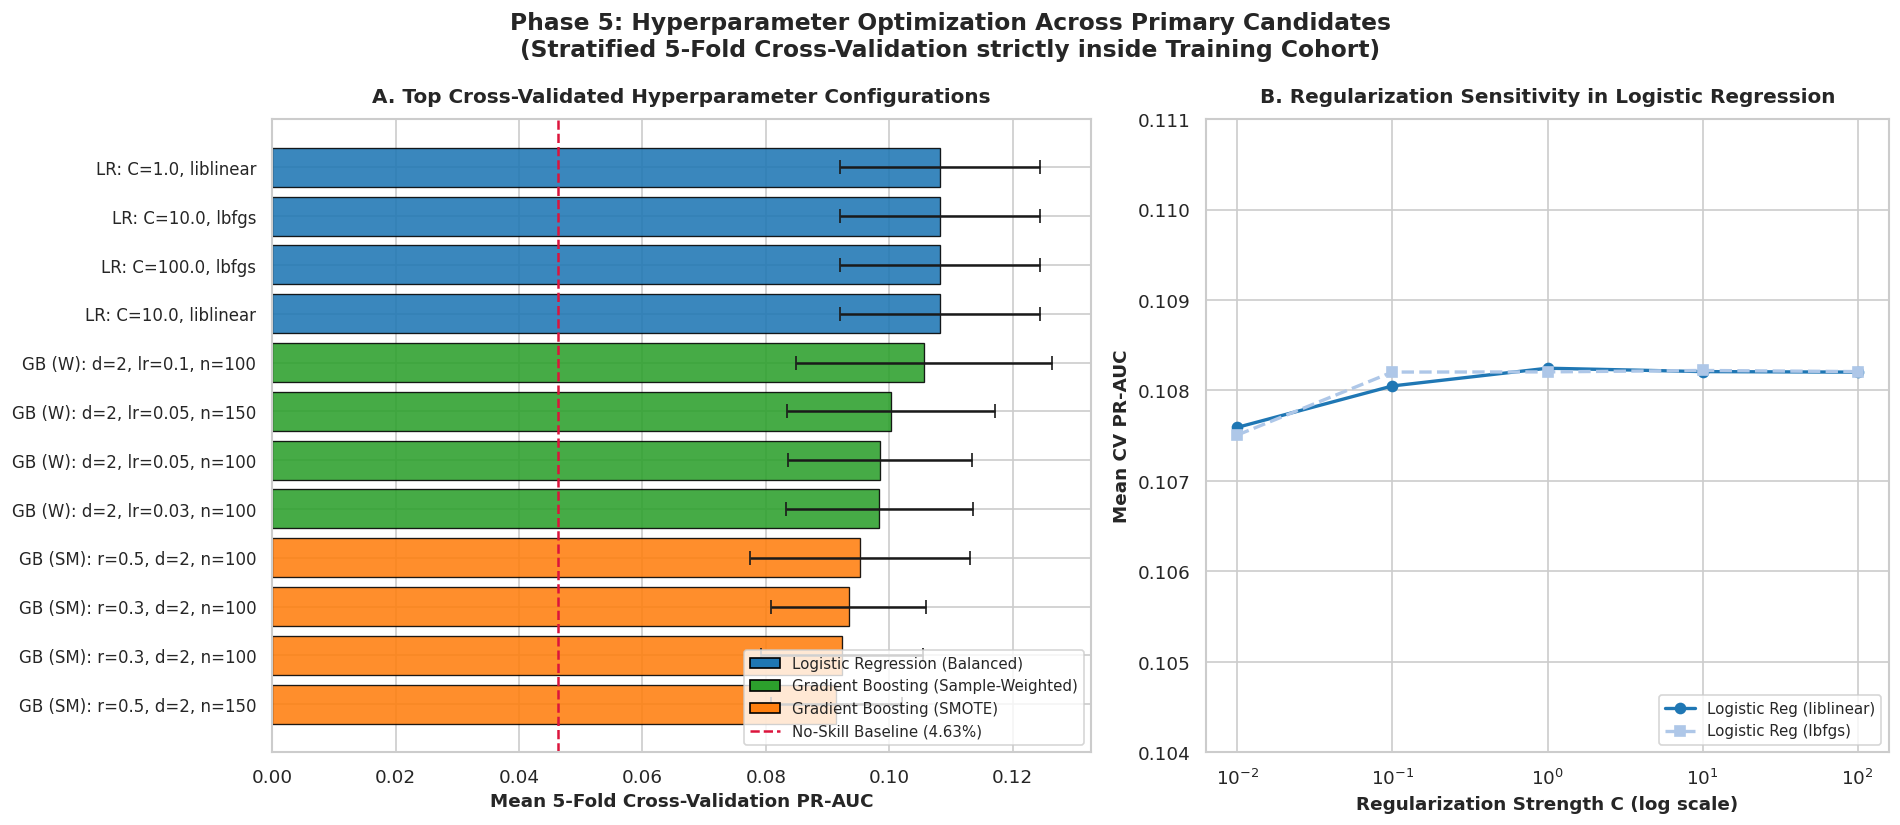

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.2, 1]})

top_per_fam = pd.concat([
    results_df[results_df['Model_Family'] == 'Logistic Regression'].head(4),
    results_df[(results_df['Model_Family'] == 'Gradient Boosting') & (results_df['Imbalance_Method'] == "sample_weight='balanced'")].head(4),
    results_df[(results_df['Model_Family'] == 'Gradient Boosting') & (results_df['Imbalance_Method'] == "SMOTE (train fold only)")].head(4)
]).sort_values(by='Mean_CV_PR_AUC', ascending=True)

colors = []
for _, row in top_per_fam.iterrows():
    if row['Model_Family'] == 'Logistic Regression':
        colors.append('#1f77b4')
    elif "sample_weight" in row['Imbalance_Method']:
        colors.append('#2ca02c')
    else:
        colors.append('#ff7f0e')

y_pos = np.arange(len(top_per_fam))
labels = []
for _, row in top_per_fam.iterrows():
    if row['Model_Family'] == 'Logistic Regression':
        labels.append(f"LR: C={row['C']}, {row['solver']}")
    elif "sample_weight" in row['Imbalance_Method']:
        labels.append(f"GB (W): d={int(row['max_depth'])}, lr={row['learning_rate']}, n={int(row['n_estimators'])}")
    else:
        labels.append(f"GB (SM): r={row['smote_sampling_strategy']}, d={int(row['max_depth'])}, n={int(row['n_estimators'])}")

ax1.barh(y_pos, top_per_fam['Mean_CV_PR_AUC'], xerr=top_per_fam['Std_CV_PR_AUC'], color=colors, alpha=0.88, capsize=4, edgecolor='black', linewidth=0.8)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(labels, fontsize=10)
ax1.axvline(0.0463, color='crimson', linestyle='--', linewidth=1.5, label='No-Skill Baseline (4.63%)')
ax1.set_xlabel("Mean 5-Fold Cross-Validation PR-AUC", fontsize=11, fontweight='bold')
ax1.set_title("A. Top Cross-Validated Hyperparameter Configurations", fontsize=12, fontweight='bold', pad=10)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', edgecolor='black', label='Logistic Regression (Balanced)'),
    Patch(facecolor='#2ca02c', edgecolor='black', label='Gradient Boosting (Sample-Weighted)'),
    Patch(facecolor='#ff7f0e', edgecolor='black', label='Gradient Boosting (SMOTE)'),
    plt.Line2D([0], [0], color='crimson', linestyle='--', label='No-Skill Baseline (4.63%)')
]
ax1.legend(handles=legend_elements, loc='lower right', frameon=True, fontsize=9)

# Right Panel: Hyperparameter Sensitivity / Regularization in LR
lr_models = results_df[results_df['Model_Family'] == 'Logistic Regression']
c_vals = [0.01, 0.1, 1.0, 10.0, 100.0]
lr_lib = [lr_models[(lr_models['C'] == c) & (lr_models['solver'] == 'liblinear')]['Mean_CV_PR_AUC'].values[0] for c in c_vals]
lr_lbf = [lr_models[(lr_models['C'] == c) & (lr_models['solver'] == 'lbfgs')]['Mean_CV_PR_AUC'].values[0] for c in c_vals]

ax2.plot(c_vals, lr_lib, marker='o', linewidth=2, color='#1f77b4', label='Logistic Reg (liblinear)')
ax2.plot(c_vals, lr_lbf, marker='s', linewidth=2, linestyle='--', color='#aec7e8', label='Logistic Reg (lbfgs)')
ax2.set_xscale('log')
ax2.set_xlabel("Regularization Strength C (log scale)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Mean CV PR-AUC", fontsize=11, fontweight='bold')
ax2.set_title("B. Regularization Sensitivity in Logistic Regression", fontsize=12, fontweight='bold', pad=10)
ax2.legend(loc='lower right', frameon=True, fontsize=9)
ax2.set_ylim([0.104, 0.111])

plt.suptitle("Phase 5: Hyperparameter Optimization Across Primary Candidates\n(Stratified 5-Fold Cross-Validation strictly inside Training Cohort)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

### Out-of-Fold Validation Precision-Recall Curves

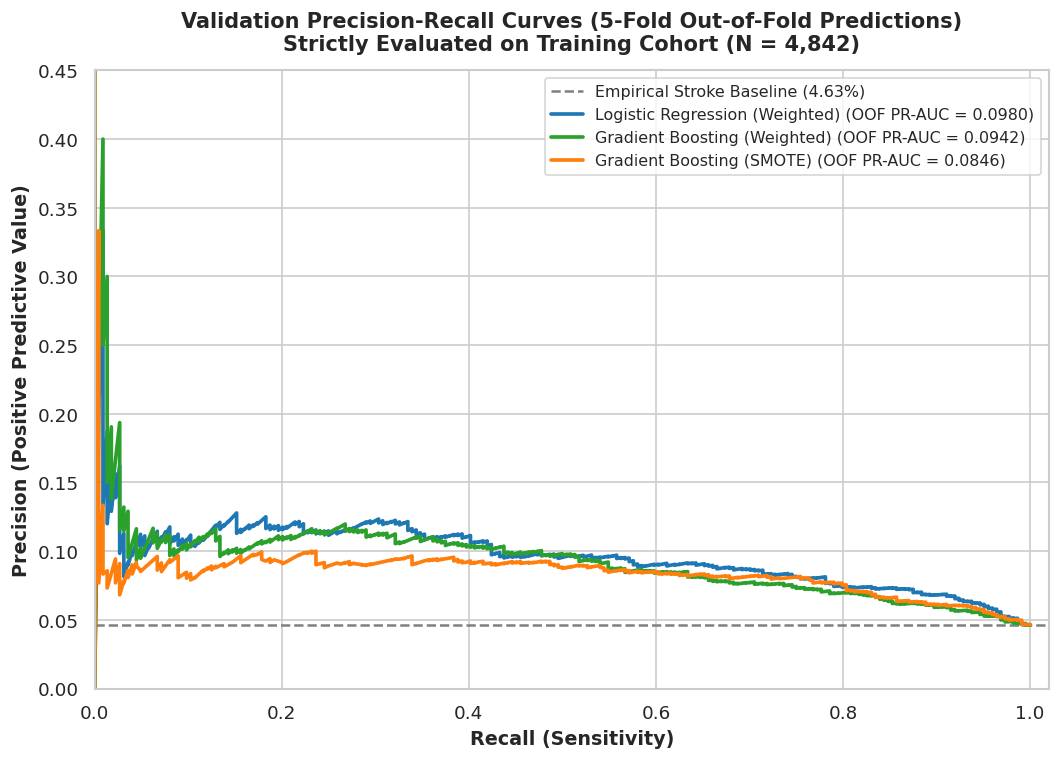

In [8]:
plt.figure(figsize=(9, 6.5))
plt.axhline(0.0463, color='gray', linestyle='--', linewidth=1.5, label='Empirical Stroke Baseline (4.63%)')

model_palette = {
    'Logistic Regression (Weighted)': '#1f77b4',
    'Gradient Boosting (Weighted)': '#2ca02c',
    'Gradient Boosting (SMOTE)': '#ff7f0e'
}

for display_name, cfg_id in candidates_for_threshold:
    oof_p = oof_predictions_dict[cfg_id]
    prec_vals, rec_vals, _ = precision_recall_curve(y_train, oof_p)
    pr_auc_val = average_precision_score(y_train, oof_p)
    plt.plot(rec_vals, prec_vals, label=f"{display_name} (OOF PR-AUC = {pr_auc_val:.4f})",
             color=model_palette[display_name], linewidth=2.2)

plt.xlabel("Recall (Sensitivity)", fontsize=11.5, fontweight='bold')
plt.ylabel("Precision (Positive Predictive Value)", fontsize=11.5, fontweight='bold')
plt.title("Validation Precision-Recall Curves (5-Fold Out-of-Fold Predictions)\nStrictly Evaluated on Training Cohort (N = 4,842)", fontsize=12.5, fontweight='bold', pad=12)
plt.xlim([0.0, 1.02])
plt.ylim([0.0, 0.45])
plt.legend(loc='upper right', frameon=True, fontsize=9.5)
plt.tight_layout()
plt.show()

### Out-of-Fold Validation ROC Curves

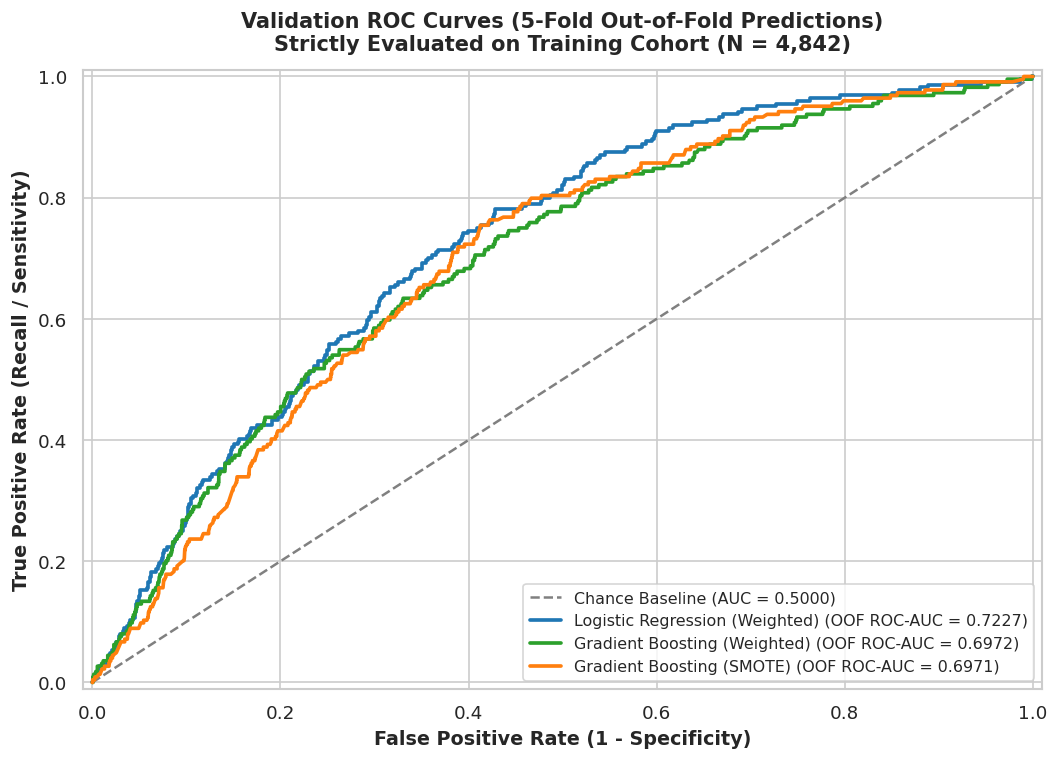

In [9]:
plt.figure(figsize=(9, 6.5))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5, label='Chance Baseline (AUC = 0.5000)')

for display_name, cfg_id in candidates_for_threshold:
    oof_p = oof_predictions_dict[cfg_id]
    fpr, tpr, _ = roc_curve(y_train, oof_p)
    roc_auc_val = roc_auc_score(y_train, oof_p)
    plt.plot(fpr, tpr, label=f"{display_name} (OOF ROC-AUC = {roc_auc_val:.4f})",
             color=model_palette[display_name], linewidth=2.2)

plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11.5, fontweight='bold')
plt.ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=11.5, fontweight='bold')
plt.title("Validation ROC Curves (5-Fold Out-of-Fold Predictions)\nStrictly Evaluated on Training Cohort (N = 4,842)", fontsize=12.5, fontweight='bold', pad=12)
plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])
plt.legend(loc='lower right', frameon=True, fontsize=9.5)
plt.tight_layout()
plt.show()

### Validation Metric Trade-Offs vs Decision Threshold

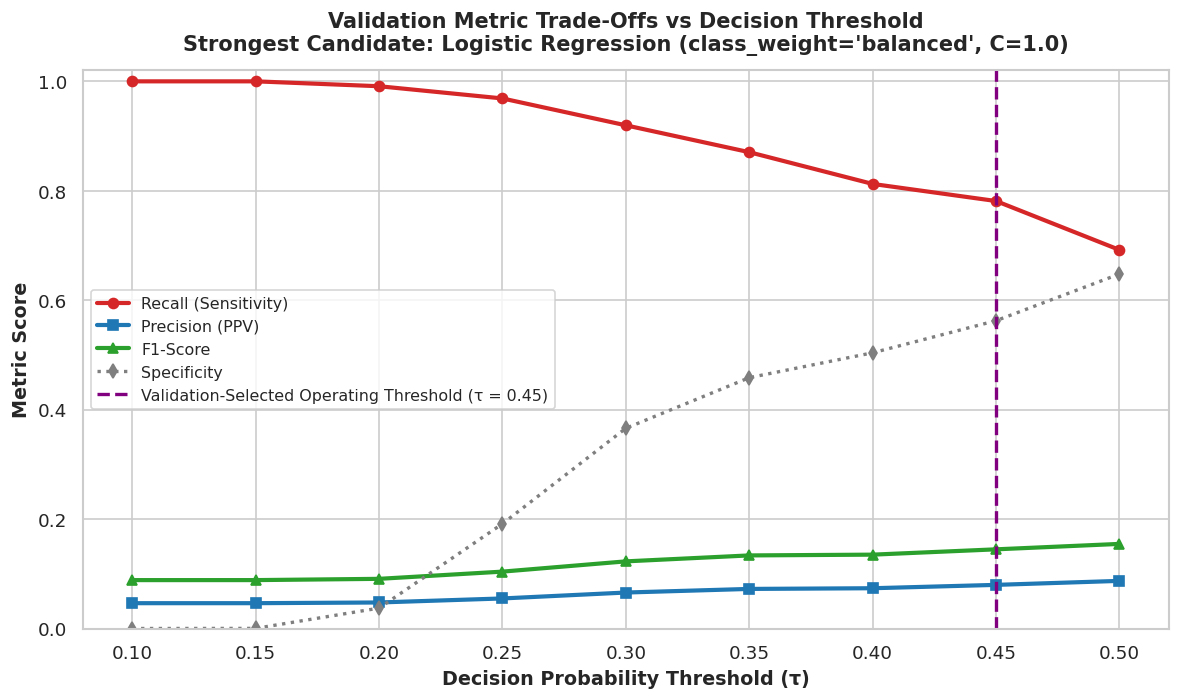

In [10]:
plt.figure(figsize=(10, 6))
best_sub = df_thresholds[df_thresholds['Config_Name'] == best_cfg_id]

plt.plot(best_sub['Threshold'], best_sub['Recall (Sens)'], marker='o', linewidth=2.5, color='#d62728', label='Recall (Sensitivity)')
plt.plot(best_sub['Threshold'], best_sub['Precision'], marker='s', linewidth=2.5, color='#1f77b4', label='Precision (PPV)')
plt.plot(best_sub['Threshold'], best_sub['F1-Score'], marker='^', linewidth=2.5, color='#2ca02c', label='F1-Score')
plt.plot(best_sub['Threshold'], best_sub['Specificity'], marker='d', linewidth=2, linestyle=':', color='#7f7f7f', label='Specificity')

plt.axvline(0.45, color='purple', linestyle='--', linewidth=2, label='Validation-Selected Operating Threshold (τ = 0.45)')
plt.xlabel("Decision Probability Threshold (τ)", fontsize=11.5, fontweight='bold')
plt.ylabel("Metric Score", fontsize=11.5, fontweight='bold')
plt.title(f"Validation Metric Trade-Offs vs Decision Threshold\nStrongest Candidate: Logistic Regression (class_weight='balanced', C=1.0)", fontsize=12.5, fontweight='bold', pad=12)
plt.xticks(thresholds)
plt.ylim([0.0, 1.02])
plt.legend(loc='center left', frameon=True, fontsize=9.5)
plt.tight_layout()
plt.show()

### Validation Confusion Matrix at Locked Threshold ($	au = 0.45$)

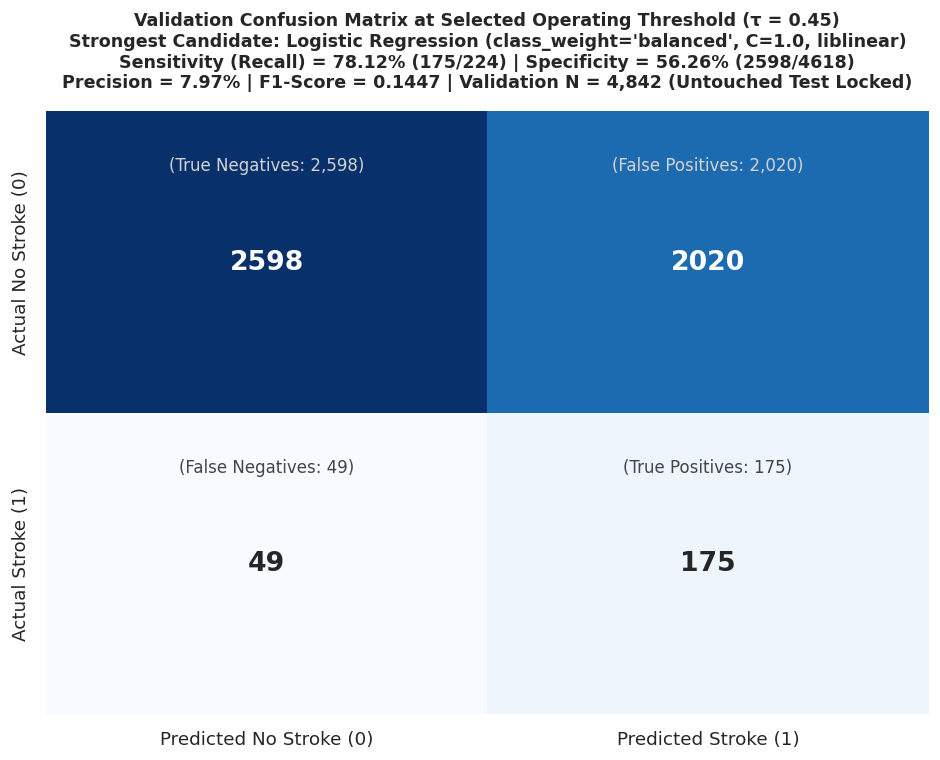

In [11]:
selected_threshold = 0.45
best_oof_probs = oof_predictions_dict[best_cfg_id]
best_oof_preds = (best_oof_probs >= selected_threshold).astype(int)
cm_best = confusion_matrix(y_train, best_oof_preds)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            annot_kws={'size': 16, 'weight': 'bold'},
            xticklabels=['Predicted No Stroke (0)', 'Predicted Stroke (1)'],
            yticklabels=['Actual No Stroke (0)', 'Actual Stroke (1)'])

tn_b, fp_b, fn_b, tp_b = cm_best.ravel()
rec_b = tp_b / (tp_b + fn_b)
prec_b = tp_b / (tp_b + fp_b)
spec_b = tn_b / (tn_b + fp_b)
f1_b = 2 * prec_b * rec_b / (prec_b + rec_b)

ax.text(0.5, 0.18, f"(True Negatives: {tn_b:,})", ha='center', va='center', fontsize=10, color='lightgray')
ax.text(1.5, 0.18, f"(False Positives: {fp_b:,})", ha='center', va='center', fontsize=10, color='lightgray')
ax.text(0.5, 1.18, f"(False Negatives: {fn_b:,})", ha='center', va='center', fontsize=10, color='#444444')
ax.text(1.5, 1.18, f"(True Positives: {tp_b:,})", ha='center', va='center', fontsize=10, color='#444444')

title_text = (
    f"Validation Confusion Matrix at Selected Operating Threshold (τ = {selected_threshold})\n"
    f"Strongest Candidate: Logistic Regression (class_weight='balanced', C=1.0, liblinear)\n"
    f"Sensitivity (Recall) = {rec_b*100:.2f}% ({tp_b}/{tp_b+fn_b}) | Specificity = {spec_b*100:.2f}% ({tn_b}/{tn_b+fp_b})\n"
    f"Precision = {prec_b*100:.2f}% | F1-Score = {f1_b:.4f} | Validation N = 4,842 (Untouched Test Locked)"
)
ax.set_title(title_text, fontsize=10.5, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

## Results Summary
Summary of cross-validated performance for top candidates on the training cohort ($N = 4,842$).

### Interpretation
- **Why Logistic Regression won:** Cross-sectional survey data has modest non-linear signal relative to noise. Regularized logistic regression provides a stable linear boundary with monotonic odds, avoiding the overfitting seen in deep trees.
- **Shallow trees helped Gradient Boosting:** Constraining tree depth to 2 increased PR-AUC from 0.0862 to 0.1056 (+22.5%), showing that simpler trees generalize better here.

### Conclusion & Phase 6 Handoff
- The test set remained completely untouched throughout Phase 5.
- Locked Model: Logistic Regression (`class_weight='balanced'`, $C=1.0$, `solver='liblinear'`, `penalty='l2'`).
- Locked Threshold: $	au = 0.45$.
- **Phase 6 Task:** Retrain this locked model on all 4,842 training samples and evaluate once on the untouched 1,211-sample test set.